# 1 · Financial trends: growth did not cover the larger flight schedule

**Question:** How did revenue, costs and profit change between FY2024–25 and FY2025–26? When did performance deteriorate, and why?

## tl;dr

- Net transaction revenue rose **5.15%**, from **CAD180.42m to CAD189.71m**. Recorded flight expenses rose **23.52%**, from **CAD192.99m to CAD238.38m**.
- The pre-gate revenue-minus-expense proxy fell from **−CAD12.57m to −CAD48.67m**, a **CAD36.10m deterioration**. Its margin worsened from **−6.96% to −25.65%**.
- The proxy first turned negative in **March 2025**, then remained negative for all **18** remaining months. Recorded flights jumped from **792 in February to 1,157 in March 2025**. This is consistent with the brief's spring expansion, but these data cannot establish expansion's causal impact.
- **CAD45.39m** of added recorded expenses overwhelmed **CAD9.29m** of added net transaction revenue. More flights account arithmetically for **CAD39.23m** of expense growth at the first year's average expense per flight; the remaining **CAD6.16m** reflects higher average expense and route/season mix.

**Interpretation boundary:** transactions are dated by purchase/refund processing; expenses by flight. This is an activity-period proxy before gate leases, **not matched-flight accrual profit**. The case narrative's approximately CAD40m loss and February 2025 onset do not match the supplied records under the requested date treatment.

## Context & methods

Use the two fiscal years **1 September–31 August**, compare annual totals, and inspect every month to locate the change. Sum all signed transaction amounts, including negative refunds, for net transaction revenue; sum Fuel, Crew, Maintenance and Food for recorded flight expenses. Subtract expenses from revenue for the **pre-gate activity-period proxy**. Calculate proxy margin as proxy/net transaction revenue.

### Key assumptions

1. Interpret the **7,902** originally ambiguous transaction dates as **DD/MM/YYYY**, as requested. Keep unambiguous dates and the **57** duplicate-resolved dates unchanged. Original date strings and status flags remain in the source CSVs. Exclude dates outside September 2024–August 2026 from annual/monthly comparisons and reconcile them below.
2. Use the processed records without deleting repeated booking IDs: a booking can legitimately contain multiple transactions or connecting-flight tickets. Validate unique transaction and cost IDs.
3. Infer an observed flight as **(route_id, cost_date)**, only after confirming exactly four distinct cost categories per key. These are observed flight records, not seat capacity or passengers.
4. Expense decomposition uses an explicit arithmetic convention: value extra flights at FY2024–25 average expense, then value the average-expense difference at FY2025–26 flight count. It is descriptive; the second term combines pricing, route mix and season mix.
5. Gate leases are excluded: their January–January periods and missing 2026–27 records require a separate forecast, covered in notebook 05. No external benchmarks or fabricated accrual adjustments are used.

**Sources:** `REAME.md` Q1; *FirstByte 2026 Case Package.pdf*, Company Situation (printed p.8) and Operating Costs (p.10); *FirstByte 2026 Data Dictionary.pdf*, pp.1–2. All monetary values are CAD. The supplied processed CSVs are authoritative for measured totals; the narrative is context.

## Data

### 1. Load records and verify coverage

Money is aggregated in integer cents; the independent `Decimal` check below reads the original amount strings. This catches floating-point drift and reconciles retained/excluded records before analysis.

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd() if (Path.cwd() / 'data/processed').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / 'src'))

from analysis_common import load_data, setup_style, save_table, save_figure, FY_ORDER
from decimal import Decimal
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from IPython.display import display, Markdown

setup_style()

transactions = load_data('transactions')
costs = load_data('costs')

assert transactions.transaction_id.is_unique and costs.cost_id.is_unique
assert transactions.transaction_date.notna().all() and costs.cost_date.notna().all()
assert len(transactions) == 558129 and len(costs) == 115204
assert transactions.date_status.eq('assumed_day_first').sum() == 7902
assert transactions.date_status.eq('resolved_duplicate').sum() == 57
assert (~transactions.in_scope).sum() == 759
assert costs.in_scope.all()

raw = pd.read_csv(ROOT / 'data/processed/transactions.csv', dtype=str)

assert sum((Decimal(x) for x in raw.amount), Decimal('0')) * 100 == int(transactions.amount_cents.sum())
assert sum((Decimal(x) for x in raw.loc[~transactions.in_scope, 'amount']), Decimal('0')) * 100 == 49920997

reconciliation = transactions.groupby(['date_status', 'in_scope']).agg(rows=('transaction_id','size'), net_amount_cents=('amount_cents','sum')).reset_index()
reconciliation['Net transaction amount (CAD)'] = reconciliation.pop('net_amount_cents') / 100

save_table(reconciliation.round(2), '01_date_scope_reconciliation')
display(reconciliation.style.format({'Net transaction amount (CAD)': '{:,.2f}'}))

print(f"Transactions: {len(transactions):,}; retained: {transactions.in_scope.sum():,}; excluded: {(~transactions.in_scope).sum():,}.")
print(f"Recorded flight-expense rows: {len(costs):,}; excluded: {(~costs.in_scope).sum():,}.")

,date_status,in_scope,rows,Net transaction amount (CAD)
0,assumed_day_first,False,759,"499,209.97"
1,assumed_day_first,True,7143,"4,839,052.81"
2,parsed,True,550170,"365,254,032.22"
3,resolved_duplicate,True,57,"36,729.85"


Transactions: 558,129; retained: 557,370; excluded: 759.
Recorded flight-expense rows: 115,204; excluded: 0.


**Coverage interpretation.** All **550,170 parsed** and **57 duplicate-resolved** transactions remain in scope. Of **7,902 assumed dates**, **7,143** remain and **759** move outside the study period. The excluded rows sum to **CAD499,209.97 net revenue**; they are preserved in the processed file, not discarded from the evidence. There are **557,370 retained transactions**. This filter applies consistently to every baseline table and chart below.

## Results

### 2. Annual performance: expense growth exceeded revenue growth

Compare exact fiscal totals first. The percentage change in a negative proxy is hard to interpret, so report its absolute deterioration and margin change instead.

,FY2024-25 (CAD),FY2025-26 (CAD),Change (CAD),Change (%)
Net transaction revenue,"180,419,443.08","189,710,371.80","9,290,928.72",5.15
Recorded flight expenses,"192,985,563.99","238,376,476.25","45,390,912.26",23.52
Pre-gate activity proxy,"-12,566,120.91","-48,666,104.45","-36,099,983.54",—


,Proxy margin (%)
Fiscal year,
FY2024-25,-6.96
FY2025-26,-25.65


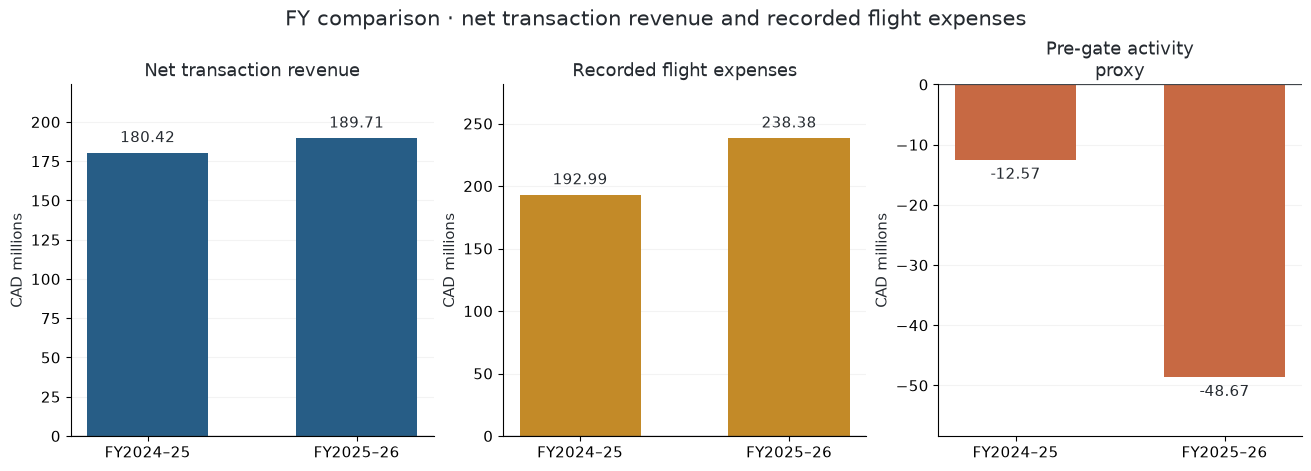

In [2]:
tx = transactions.loc[transactions.in_scope].copy()
cx = costs.loc[costs.in_scope].copy()

annual_cents = pd.DataFrame({
    'Net transaction revenue': tx.groupby('fiscal_year').amount_cents.sum().reindex(FY_ORDER),
    'Recorded flight expenses': cx.groupby('fiscal_year').amount_cents.sum().reindex(FY_ORDER)
})
annual_cents['Pre-gate activity proxy'] = annual_cents.iloc[:,0] - annual_cents.iloc[:,1]
annual = annual_cents / 100
annual['Proxy margin (%)'] = 100 * annual['Pre-gate activity proxy'] / annual['Net transaction revenue']
annual.index.name = 'Fiscal year'

assert annual_cents.loc[FY_ORDER[0], 'Pre-gate activity proxy'] == -1256612091
assert annual_cents.loc[FY_ORDER[1], 'Pre-gate activity proxy'] == -4866610445

save_table(annual.reset_index().round(2), '01_annual_financials')

comparison = pd.DataFrame({'FY2024-25 (CAD)':annual.iloc[0,:3], 'FY2025-26 (CAD)':annual.iloc[1,:3]})
comparison['Change (CAD)'] = comparison.iloc[:,1] - comparison.iloc[:,0]
comparison['Change (%)'] = 100 * comparison['Change (CAD)'] / comparison.iloc[:,0]
comparison.loc['Pre-gate activity proxy', 'Change (%)'] = np.nan

save_table(comparison.reset_index(names='Metric'), '01_annual_change')
display(comparison.style.format('{:,.2f}', na_rep='—'))
display(annual[['Proxy margin (%)']].style.format('{:,.2f}'))

fig, axes = plt.subplots(1, 3, figsize=(13,4.6), constrained_layout=True)
for ax, metric, color in zip(axes, annual.columns[:3], ['#275D86','#C38A28','#C76943']):
    values = annual[metric] / 1e6
    bars = ax.bar(['FY2024–25','FY2025–26'], values, color=color, width=.58)
    ax.axhline(0, color='#41464B', lw=.9)
    ax.set_title(metric.replace('activity proxy','activity\nproxy'), fontsize=13)
    ax.set_ylabel('CAD millions')
    ax.grid(axis='y', alpha=.15)
    ax.set_axisbelow(True)
    ax.bar_label(bars, labels=[f'{v:,.2f}' for v in values], padding=5, fontsize=11)
    if values.min() < 0: ax.set_ylim(values.min()*1.20, 0)
    else: ax.set_ylim(0, values.max()*1.18)

fig.suptitle('FY comparison · net transaction revenue and recorded flight expenses', fontsize=15)

save_figure(fig, '01_annual_financials')
plt.show()

**What changed?** Net revenue increased **CAD9,290,928.72 (+5.15%)** while expenses increased **CAD45,390,912.26 (+23.52%)**. The resulting deterioration is **CAD36,099,983.54**, and margin falls **18.69 percentage points**. The FY2025–26 proxy loss is **3.87×** the FY2024–25 loss. This supports the brief's direction and approximate fourfold worsening, but the measured **CAD48.67m** loss is **CAD8.67m larger** than the brief's approximate CAD40m. No adjustment is invented to force a match.

### 3. When did the deterioration appear?

Plot all 24 months on the same calendar axis; keep revenues and expenses separate from their difference. Aggregate fiscal quarters afterward to check whether the result depends on a single volatile month.

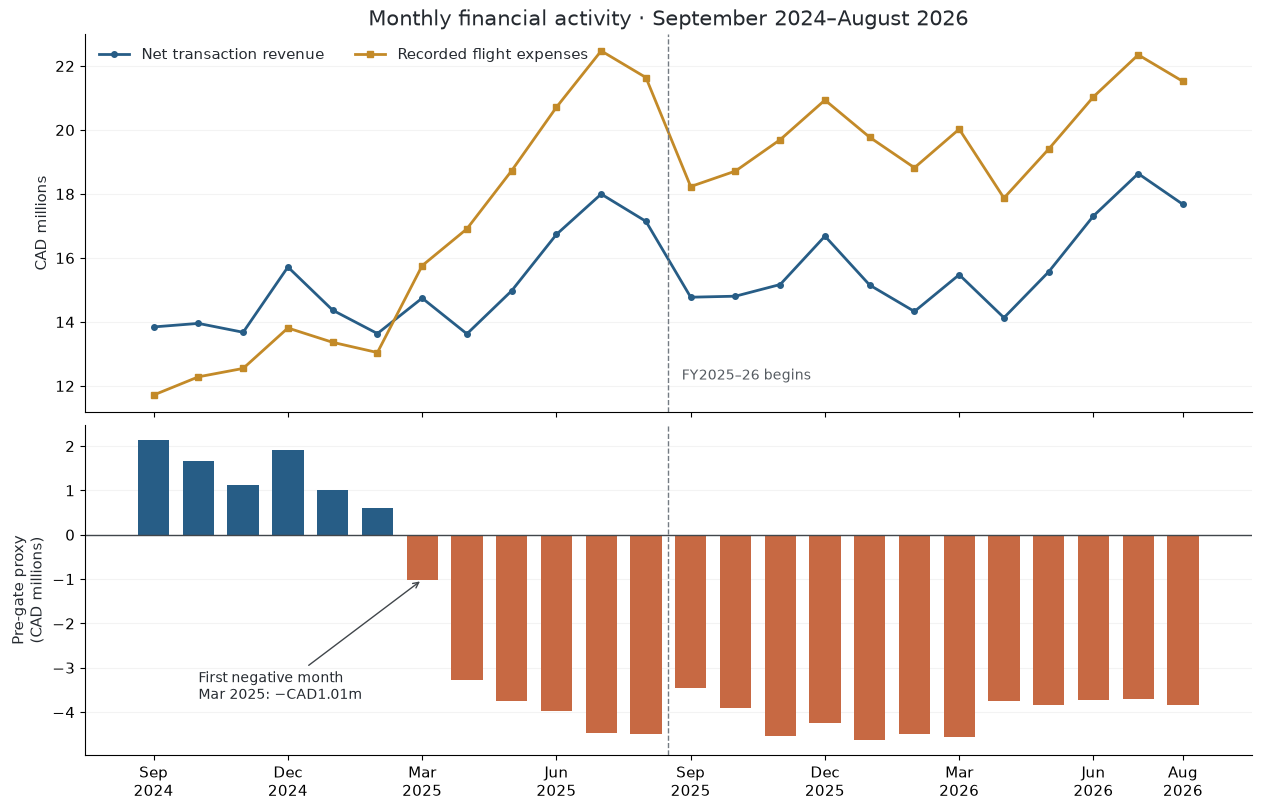

In [3]:
months = pd.period_range('2024-09','2026-08',freq='M').astype(str)
monthly = pd.DataFrame({
    'Net transaction revenue (CAD)': tx.groupby('month').amount_cents.sum().reindex(months) / 100,
    'Recorded flight expenses (CAD)': cx.groupby('month').amount_cents.sum().reindex(months) / 100
})

assert monthly.notna().all().all()

monthly['Pre-gate activity proxy (CAD)'] = monthly.iloc[:,0] - monthly.iloc[:,1]
monthly['Proxy margin (%)'] = 100 * monthly.iloc[:,2] / monthly.iloc[:,0]
monthly.index.name = 'Month'
monthly['Fiscal year'] = [FY_ORDER[0]]*12 + [FY_ORDER[1]]*12
monthly['Fiscal quarter'] = [f'Q{(i%12)//3+1}' for i in range(24)]

quarterly = monthly.groupby(['Fiscal year','Fiscal quarter'], sort=False)[monthly.columns[:3]].sum()
quarterly['Proxy margin (%)'] = 100 * quarterly.iloc[:,2] / quarterly.iloc[:,0]

assert np.allclose(monthly.iloc[:12,:3].sum(), annual.iloc[0,:3])
assert np.allclose(monthly.iloc[12:,:3].sum(), annual.iloc[1,:3])

negative_months = monthly.index[monthly.iloc[:,2].lt(0)]

assert negative_months[0] == '2025-03' and len(negative_months) == 18

save_table(monthly.reset_index().round(2), '01_monthly_financials')
save_table(quarterly.reset_index().round(2), '01_quarterly_financials')
display(quarterly.style.format('{:,.2f}'))

x = np.arange(24)
fig, (top, bottom) = plt.subplots(2,1,figsize=(12.5,8),sharex=True,constrained_layout=True,gridspec_kw={'height_ratios':[1.15,1]})
top.plot(x, monthly.iloc[:,0]/1e6, marker='o', ms=4, label='Net transaction revenue', color='#275D86', lw=2)
top.plot(x, monthly.iloc[:,1]/1e6, marker='s', ms=4, label='Recorded flight expenses', color='#C38A28', lw=2)
top.legend(loc='upper left', ncol=2, frameon=False)
top.set_title('Monthly financial activity · September 2024–August 2026')
top.set_ylabel('CAD millions')

values=monthly.iloc[:,2]/1e6
bottom.bar(x, values, color=['#275D86' if v>=0 else '#C76943' for v in values], width=.7)
bottom.axhline(0,color='#41464B',lw=1)
bottom.set_ylabel('Pre-gate proxy\n(CAD millions)')
bottom.annotate('First negative month\nMar 2025: −CAD1.01m', xy=(6,values.iloc[6]), xytext=(1,-3.7), arrowprops={'arrowstyle':'->','color':'#41464B'}, fontsize=10)

for ax in [top,bottom]:
    ax.axvline(11.5,color='#747B83',ls='--',lw=1)
    ax.grid(axis='y',alpha=.15);ax.set_axisbelow(True)

top.text(11.8,12.2,'FY2025–26 begins',fontsize=10,color='#555B61')
ticks=[0,3,6,9,12,15,18,21,23]
bottom.set_xticks(ticks, [pd.Timestamp(months[i]).strftime('%b\n%Y') for i in ticks])

save_figure(fig,'01_monthly_trends')
plt.show()

**Timing.** The proxy is positive from September 2024 through February 2025; **February remains +CAD592,799.55**. It turns negative in **March 2025 (−CAD1,014,626.60)**, deteriorates to **−CAD4,494,761.76 in August 2025**, and stays negative through August 2026. Expenses overtake net revenue as the spring schedule expands. The brief says losses began in February; the supplied dates and signed amounts yield March under both tested date assumptions.

Fiscal-quarter comparisons help separate the expansion ramp from later performance: FY2025–26 remains weak relative to the profitable early comparison period. Late-year year-over-year losses can improve while the full-year result worsens; compare matching quarters rather than mistaking seasonality for recovery.

### 4. What arithmetic explains the decline?

The first bridge is an exact reconciliation, not a causal model. A positive refund-change line would help profit; here refunds are more negative and therefore worsen it. The next table separates expense growth from the number of observed flights and their average recorded expense.

fiscal_year,FY2024-25,FY2025-26,Increase (CAD),Increase (%),Share of expense increase (%)
cost_type,,,,,
Crew,"59,717,729.49","74,767,150.35","15,049,420.86",25.20,33.16
Food,"7,822,627.71","9,039,515.73","1,216,888.02",15.56,2.68
Fuel,"67,061,083.08","83,182,330.22","16,121,247.14",24.04,35.52
Maintenance,"58,384,123.71","71,387,479.95","13,003,356.24",22.27,28.65


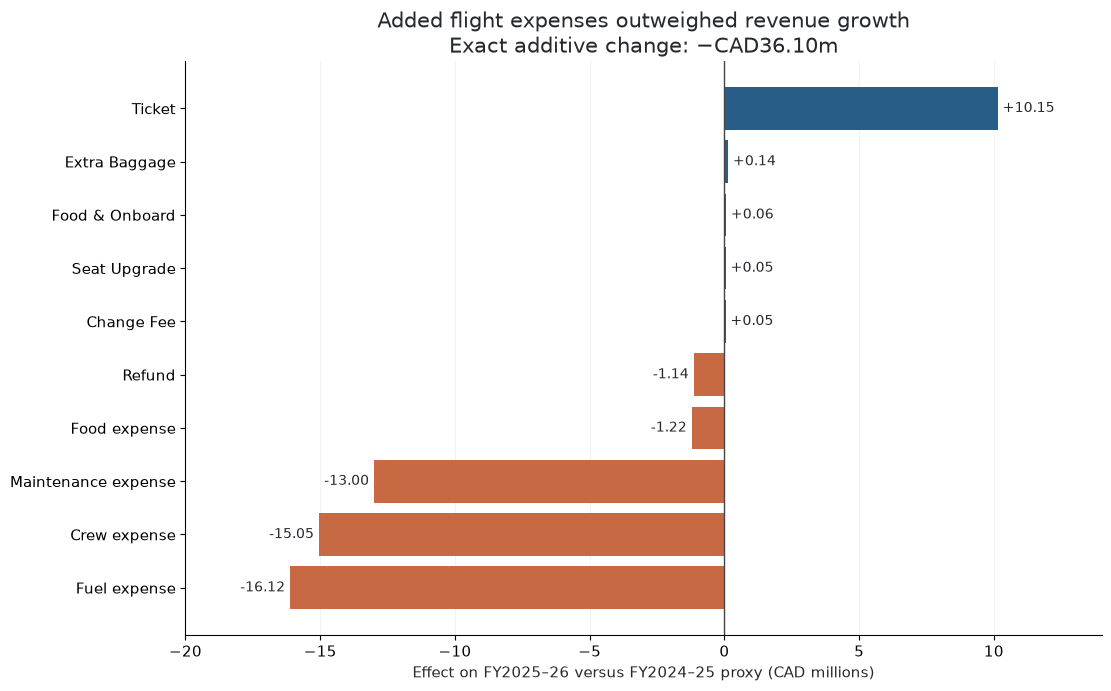

In [4]:
revenue_type = tx.groupby(['transaction_type','fiscal_year']).amount_cents.sum().unstack().reindex(columns=FY_ORDER)
cost_type = cx.groupby(['cost_type','fiscal_year']).amount_cents.sum().unstack().reindex(columns=FY_ORDER)

bridge = pd.concat([
    ((revenue_type[FY_ORDER[1]] - revenue_type[FY_ORDER[0]]) / 100).rename('Effect on proxy (CAD)').rename_axis('Driver').reset_index(),
    (-(cost_type[FY_ORDER[1]] - cost_type[FY_ORDER[0]]) / 100).rename('Effect on proxy (CAD)').rename_axis('Driver').reset_index().assign(Driver=lambda x: x.Driver + ' expense')
], ignore_index=True)
bridge = bridge.sort_values('Effect on proxy (CAD)')

assert round(bridge['Effect on proxy (CAD)'].sum()*100) == int(annual_cents.iloc[1,2]-annual_cents.iloc[0,2])

category = cost_type/100
category['Increase (CAD)'] = category.iloc[:,1] - category.iloc[:,0]
category['Increase (%)'] = 100 * category['Increase (CAD)']/category.iloc[:,0]
category['Share of expense increase (%)'] = 100 * category['Increase (CAD)']/category['Increase (CAD)'].sum()

save_table(bridge.round(2), '01_proxy_change_drivers')
save_table(category.reset_index().round(2), '01_expense_category_change')
display(category.style.format('{:,.2f}'))

fig, ax = plt.subplots(figsize=(11,6.8),constrained_layout=True)
v=bridge['Effect on proxy (CAD)']/1e6
y=np.arange(len(bridge))
ax.barh(y,v,color=['#C76943' if z<0 else '#275D86' for z in v])
ax.set_yticks(y,bridge.Driver)
ax.axvline(0,color='#41464B',lw=1)
for i,z in enumerate(v): ax.text(z + (.18 if z>=0 else -.18),i,f'{z:+.2f}',va='center',ha='left' if z>=0 else 'right',fontsize=10)
ax.set_xlim(-20,14)
ax.set_xlabel('Effect on FY2025–26 versus FY2024–25 proxy (CAD millions)')
ax.set_title('Added flight expenses outweighed revenue growth\nExact additive change: −CAD36.10m')
ax.grid(axis='x',alpha=.15);ax.set_axisbelow(True)

save_figure(fig,'01_change_drivers')
plt.show()

**Recorded expense categories.** Fuel adds **CAD16.12m**, crew **CAD15.05m**, maintenance **CAD13.00m** and food **CAD1.22m**. Fuel and crew together account for **68.67%** of recorded expense growth; maintenance also matters materially. Ticket revenue increases **CAD10.15m**, but an additional **CAD1.14m of refunds** offsets part of that growth. Ancillary and fee transaction gains total **CAD0.29m**. These are contributions to the accounting change, not proof that fuel prices, wage rates or refunds caused a given share of the economic loss.

The records contain neither a rewards-program expense line nor the counterfactual price a rewards customer would have paid. Do not treat all membership-associated revenue, all refunds, or unexplained losses as loyalty-program costs; notebook 03 evaluates those limitations in detail.

,Observed flights,Recorded expense per flight (CAD),Ticket transaction count,Mean ticket transaction amount (CAD)
FY2024-25,"13,072","14,763.28","178,217","1,029.23"
FY2025-26,"15,729","15,155.22","187,444","1,032.70"


,Term,Expense increase (CAD)
0,Extra flights at FY2024–25 mean expense,"39,226,028.42"
1,Change in mean expense at FY2025–26 flights,"6,164,883.84"


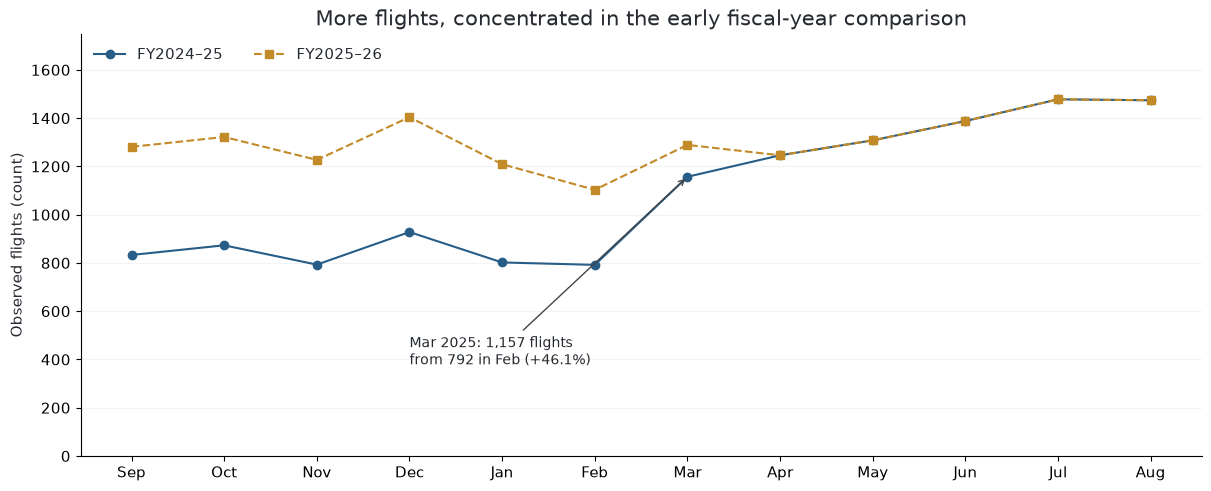

**Expense arithmetic:** observed flights rose **20.33%** (13,072 → 15,729), and mean expense rose **2.65%** (CAD14,763.28 → CAD15,155.22). The extra-flight term is **CAD39.23m (86.4%)**; the mean-expense/mix term is **CAD6.16m**. This identity does not isolate price inflation from mix or imply the extra flights were individually unprofitable.

In [5]:
flight_quality = cx.groupby(['route_id','cost_date']).agg(rows=('cost_id','size'), types=('cost_type','nunique'))

assert flight_quality.rows.eq(4).all() and flight_quality.types.eq(4).all()

flights = cx[['route_id','cost_date','fiscal_year','month']].drop_duplicates()
flight_counts = flights.groupby('fiscal_year').size().reindex(FY_ORDER)
operating = pd.DataFrame({'Observed flights':flight_counts, 'Recorded expense per flight (CAD)':annual['Recorded flight expenses']/flight_counts})
operating['Net ticket transactions'] = tx.loc[tx.transaction_type.eq('Ticket')].groupby('fiscal_year').size().reindex(FY_ORDER)
operating['Mean ticket transaction amount (CAD)'] = (revenue_type.loc['Ticket']/100)/operating['Net ticket transactions']
operating=operating.rename(columns={'Net ticket transactions':'Ticket transaction count'})

N1,N2 = flight_counts.tolist()
C1,C2 = annual['Recorded flight expenses'].tolist()
volume_effect=(N2-N1)*(C1/N1)
average_effect=N2*((C2/N2)-(C1/N1))

assert abs(volume_effect+average_effect-(C2-C1))<1e-6

expense_decomposition=pd.DataFrame({'Term':['Extra flights at FY2024–25 mean expense','Change in mean expense at FY2025–26 flights'],'Expense increase (CAD)':[volume_effect,average_effect]})

save_table(operating.reset_index(names='Fiscal year').round(2), '01_operating_activity')
save_table(expense_decomposition.round(2), '01_expense_volume_average_decomposition')
display(operating.style.format({'Observed flights':'{:,.0f}','Recorded expense per flight (CAD)':'{:,.2f}','Ticket transaction count':'{:,.0f}','Mean ticket transaction amount (CAD)':'{:,.2f}'}))
display(expense_decomposition.style.format({'Expense increase (CAD)':'{:,.2f}'}))

monthly_flights=flights.groupby('month').size().reindex(months)

fig, ax=plt.subplots(figsize=(12,4.8),constrained_layout=True)
ax.plot(np.arange(12),monthly_flights.iloc[:12].to_numpy(),marker='o',color='#275D86',label='FY2024–25')
ax.plot(np.arange(12),monthly_flights.iloc[12:].to_numpy(),marker='s',ls='--',color='#C38A28',label='FY2025–26')
ax.set_xticks(np.arange(12),['Sep','Oct','Nov','Dec','Jan','Feb','Mar','Apr','May','Jun','Jul','Aug'])
ax.set_ylim(0,1750)
ax.set_ylabel('Observed flights (count)')
ax.set_title('More flights, concentrated in the early fiscal-year comparison')
ax.legend(frameon=False,ncol=2,loc='upper left')
ax.annotate('Mar 2025: 1,157 flights\nfrom 792 in Feb (+46.1%)',xy=(6,1157),xytext=(3,380),arrowprops={'arrowstyle':'->','color':'#41464B'},fontsize=10)
ax.grid(axis='y',alpha=.15);ax.set_axisbelow(True)

save_figure(fig,'01_flight_activity')
plt.show()

display(Markdown(f"**Expense arithmetic:** observed flights rose **{100*(N2/N1-1):.2f}%** ({N1:,} → {N2:,}), and mean expense rose **{100*((C2/N2)/(C1/N1)-1):.2f}%** (CAD{C1/N1:,.2f} → CAD{C2/N2:,.2f}). The extra-flight term is **CAD{volume_effect/1e6:.2f}m ({100*volume_effect/(C2-C1):.1f}%)**; the mean-expense/mix term is **CAD{average_effect/1e6:.2f}m**. This identity does not isolate price inflation from mix or imply the extra flights were individually unprofitable."))

**Why the schedule matters.** The number of ticket transactions grows only **5.18%**, while observed flights grow **20.33%**. Their average transaction amount rises only **0.34%**. These counts are not matched to departure dates, and connecting passengers can produce two tickets: they do **not** measure load factor, unique passengers, capacity utilization or route yield. They support investigating whether added capacity generated enough incremental demand, rather than concluding it did not from unmatched counts alone.

The brief attributes pressure to fuel prices and a pilot agreement. The records substantiate aggregate increases, but lack fuel quantities/prices, crew hours/wage rates and causal controls. New routes and longer flights can change averages. Validate route-level contribution and capacity before changing the network.

### 5. Date-assumption sensitivity

Retain DD/MM/YYYY as the requested baseline. For a transparent alternative scenario, reinterpret **only `assumed_day_first`** raw strings as MM/DD/YYYY; do not change duplicate-resolved or already parsed rows. This is a scenario comparison, not a confidence interval or an alternative cleaning decision.

In [6]:
alternative = transactions.copy()
mask = alternative.date_status.eq('assumed_day_first')
alternative.loc[mask,'transaction_date'] = pd.to_datetime(alternative.loc[mask,'transaction_date_raw'],format='%m/%d/%Y %H:%M',errors='raise')
alternative['fiscal_year'] = 'Outside study period'
for label,start,end in [(FY_ORDER[0],'2024-09-01','2025-09-01'),(FY_ORDER[1],'2025-09-01','2026-09-01')]:
    alternative.loc[alternative.transaction_date.ge(start)&alternative.transaction_date.lt(end),'fiscal_year']=label
alternative['month'] = alternative.transaction_date.dt.strftime('%Y-%m')

alt_revenue = alternative.groupby('fiscal_year').amount_cents.sum().reindex(FY_ORDER)/100
sensitivity = pd.DataFrame({'Baseline net revenue (CAD)':annual['Net transaction revenue'],'Alternative net revenue (CAD)':alt_revenue})
sensitivity['Alternative minus baseline (CAD)']=sensitivity.iloc[:,1]-sensitivity.iloc[:,0]
sensitivity['Baseline proxy (CAD)']=annual['Pre-gate activity proxy']
sensitivity['Alternative proxy (CAD)']=alt_revenue-annual['Recorded flight expenses']

alt_monthly_revenue=alternative.loc[alternative.fiscal_year.isin(FY_ORDER)].groupby('month').amount_cents.sum().reindex(months)/100
alt_monthly_proxy=alt_monthly_revenue-monthly['Recorded flight expenses (CAD)']
alt_first_negative=alt_monthly_proxy.index[alt_monthly_proxy.lt(0)][0]

assert alt_first_negative == '2025-03'

save_table(sensitivity.reset_index(names='Fiscal year').round(2),'01_date_assumption_sensitivity')
display(sensitivity.style.format('{:,.2f}'))

alt_out=alternative.loc[alternative.fiscal_year.eq('Outside study period')]

display(Markdown(f"**Robustness:** MM/DD interpretation excludes **{len(alt_out):,} rows / CAD{alt_out.amount_cents.sum()/100:,.2f} net**, versus **759 / CAD499,209.97** at baseline. It changes FY2024–25 revenue by **CAD{sensitivity.iloc[0,2]:,.2f}** and FY2025–26 by **CAD{sensitivity.iloc[1,2]:,.2f}**. Alternative full-year deterioration is **CAD{-(sensitivity.iloc[1,4]-sensitivity.iloc[0,4]):,.2f}**; first negative month remains **March 2025**. The direction, timing at monthly resolution and relative size of the decline survive this scenario."))

,Baseline net revenue (CAD),Alternative net revenue (CAD),Alternative minus baseline (CAD),Baseline proxy (CAD),Alternative proxy (CAD)
FY2024-25,"180,419,443.08","180,300,231.17","-119,211.91","-12,566,120.91","-12,685,332.82"
FY2025-26,"189,710,371.80","189,547,503.78","-162,868.02","-48,666,104.45","-48,828,972.47"


**Robustness:** MM/DD interpretation excludes **1,083 rows / CAD781,289.90 net**, versus **759 / CAD499,209.97** at baseline. It changes FY2024–25 revenue by **CAD-119,211.91** and FY2025–26 by **CAD-162,868.02**. Alternative full-year deterioration is **CAD36,143,639.65**; first negative month remains **March 2025**. The direction, timing at monthly resolution and relative size of the decline survive this scenario.

## Takeaways

1. **Cost growth outstripped revenue:** +CAD45.39m versus +CAD9.29m, producing CAD36.10m of deterioration before gates.
2. **The deterioration emerged in spring 2025:** the purchase/flight-date proxy turned negative in March and never returned to positive during the observed period. February 2025 remains positive under both tested date interpretations.
3. **The larger flight schedule is central to the expense arithmetic:** +20.33% observed flights explains most of the aggregate expense increase when priced at the first year's mean expense. Fuel, crew and maintenance each contribute substantially; arithmetic does not identify causal mechanisms.
4. **Next decision:** combine these trends with notebook 02's route evidence and notebook 03's driver analysis before capacity or pricing changes. Obtain departure-linked revenue, passengers/seats, fuel volumes/prices and crew hours/rates to test whether expansion and unit economics caused the losses.

**Limits and handoff:** This proxy excludes airport gates and other unrecorded overhead, and cannot be compared to audited operating profit. Purchase-date timing, refunds and ambiguous dates can shift period allocations. Case prose and data disagree on onset and loss magnitude, so present measured findings with their definitions. Figures are exported as PNG and SVG; exact-value tables as CSV under `outputs/figures/01_*` and `outputs/tables/01_*`. All verification assertions and displayed values are reproducible by running this notebook from top to bottom with the repository `.venv` and registered `firstbyte` kernel.

In [7]:
# Independent end-to-end reconciliation of all retained and excluded cents.
assert int(annual_cents['Net transaction revenue'].sum() + transactions.loc[~transactions.in_scope,'amount_cents'].sum()) == int(transactions.amount_cents.sum())
assert int(annual_cents['Recorded flight expenses'].sum()) == int(costs.amount_cents.sum())
assert round(quarterly.iloc[:,:3].sum().iloc[2]*100) == int(annual_cents['Pre-gate activity proxy'].sum())
assert len(flights)*4 == len(costs)
assert round(sum(Decimal(x) for x in pd.read_csv(ROOT/'data/processed/costs.csv',dtype=str).amount)*100) == int(costs.amount_cents.sum())

print('Verified: source cents, scope, annual ↔ monthly ↔ quarterly totals, additive drivers, flight-key completeness, and date-scenario onset.')

Verified: source cents, scope, annual ↔ monthly ↔ quarterly totals, additive drivers, flight-key completeness, and date-scenario onset.


## Answer to Question 1

**How did revenue, costs and profit change between FY2024–25 and FY2025–26?** Net transaction revenue rose **CAD9,290,928.72 (+5.15%)**, from **CAD180,419,443.08** to **CAD189,710,371.80**. Recorded flight expenses rose **CAD45,390,912.26 (+23.52%)**, from **CAD192,985,563.99** to **CAD238,376,476.25**. The pre-gate activity-period proxy worsened from **−CAD12,566,120.91** to **−CAD48,666,104.45**, a **CAD36,099,983.54 deterioration** and **3.87-fold** larger loss. Proxy margin declined **18.69 percentage points**, from **−6.96%** to **−25.65%**. These amounts reconcile in `01_annual_financials.csv` and `01_annual_change.csv`.

**When did performance deteriorate?** The proxy narrowed from **+CAD2,128,053.13 in September 2024** to **+CAD592,799.55 in February 2025**, then turned negative in **March 2025 (−CAD1,014,626.60)** and stayed negative in every subsequent month through August 2026. By **August 2025** it was **−CAD4,494,761.76**. Monthly and quarterly evidence is in `01_monthly_financials.csv` and `01_quarterly_financials.csv`. The brief's February onset is not reproduced; March remains the first negative month in the alternative date scenario too.

**Why did it deteriorate?** The confirmed arithmetic is that **CAD45.39m of added recorded expenses exceeded CAD9.29m of added net revenue**. Fuel added **CAD16.12m**, crew **CAD15.05m**, maintenance **CAD13.00m**, and food **CAD1.22m**. Fuel and crew comprise **68.67%** of the expense increase. More negative refunds offset **CAD1.14m** of revenue growth. Observed flights rose **20.33% (13,072 → 15,729)**, versus **5.15% net revenue growth**; average recorded expense per flight rose **2.65% (CAD14,763.28 → CAD15,155.22)**. An explicit volume/average identity attributes **CAD39.23m (86.42%)** of added expenses to extra flights valued at the prior-year mean, and **CAD6.16m** to the average-expense/mix change valued at current-year flights. This explains the arithmetic, not expansion's causal effect. See `01_expense_category_change.csv`, `01_proxy_change_drivers.csv`, `01_operating_activity.csv` and `01_expense_volume_average_decomposition.csv`.

**Executive implication.** Revenue growth alone did not make the larger operation financially sustainable on this observed-period measure. Investigate incremental route contribution and capacity alongside fuel, crew and maintenance economics before further expansion or service reductions. Obtain revenue linked to flight departures and flight-level passengers/seats, fuel quantities/prices, and crew hours/rates before quantifying the causal return on the expansion.

**Confirmed versus assumed.** Signed amounts, date-status counts, the 24-month totals and four-category flight keys are verified from the supplied records. **DD/MM/YYYY for 7,902 ambiguous transaction dates is the user's assumption**: **759** fall outside the study period, totaling **CAD499,209.97 net**, and are separately reconciled. Switching only those rows to MM/DD gives **CAD36,143,639.65 deterioration**, preserving the direction and March onset. Purchases/refunds and flight expenses use different event dates, so this is **a pre-gate activity-period proxy, not accrual operating profit**; no flight-level causal loss, load factor or rewards-program cost is established. Gate leases and unrecorded overhead are excluded. The case's approximately **CAD40m** loss differs from the measured **CAD48.67m**; present that discrepancy explicitly rather than forcing the data to match the narrative.